# SmartAnswer — Answer Sentence Selection on WikiQA

**NLP Task:** Answer Sentence Selection (a sub-task of Question Answering)

**Objective:** Given a question and a set of candidate sentences, predict/rank
which sentence correctly answers the question.

**Models compared (7 total):** Logistic Regression, Random Forest, Gradient
Boosting, SVM, MLP, LSTM, BERT (classifier only — not generative AI)

**Dataset:** WikiQA — 29,208 (question, sentence) rows, 3,044 questions

## 1. Setup & Imports

In [1]:
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")

## 2. Load the Dataset

`encoding="utf-8-sig"` handles the BOM character at the start of this CSV.

In [2]:
df_raw = pd.read_csv("WikiQA.csv", encoding="utf-8-sig")
print(f"Raw shape: {df_raw.shape}")
df_raw.head()

Raw shape: (29208, 7)


,QuestionID,Question,DocumentID,DocumentTitle,SentenceID,Sentence,Label
0,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-0,African immigration to the United States refer...,0
1,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-1,The term African in the scope of this article ...,0
2,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-2,From the Immigration and Nationality Act of 19...,0
3,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-3,African immigrants in the United States come f...,0
4,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-4,"They include people from different national, l...",0


## 3. Data Cleaning

Check for missing values, duplicates, malformed text, and invalid labels
before exploring or modeling.

In [3]:
df = df_raw.copy()
n_before = len(df)

missing_q = df["Question"].isna().sum()
missing_s = df["Sentence"].isna().sum()
print(f"Missing Question values: {missing_q}")
print(f"Missing Sentence values: {missing_s}")
df = df.dropna(subset=["Question", "Sentence"]).reset_index(drop=True)

df["Question"] = df["Question"].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
df["Sentence"] = df["Sentence"].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)

empty_q = (df["Question"].str.len() == 0).sum()
empty_s = (df["Sentence"].str.len() == 0).sum()
print(f"Empty Question after cleaning: {empty_q}")
print(f"Empty Sentence after cleaning: {empty_s}")
df = df[(df["Question"].str.len() > 0) & (df["Sentence"].str.len() > 0)].reset_index(drop=True)

n_dupes = df.duplicated(subset=["QuestionID", "Sentence"]).sum()
print(f"Duplicate (QuestionID, Sentence) rows: {n_dupes}")
df = df.drop_duplicates(subset=["QuestionID", "Sentence"]).reset_index(drop=True)

valid_labels = df["Label"].isin([0, 1])
print(f"Rows with invalid Label values: {(~valid_labels).sum()}")
df = df[valid_labels].reset_index(drop=True)

q_counts = df.groupby("QuestionID").size()
print(f"Questions with 0 candidate sentences: {(q_counts == 0).sum()}")

n_after = len(df)
print(f"\nRows before cleaning: {n_before}")
print(f"Rows after cleaning:  {n_after}")
print(f"Rows removed:         {n_before - n_after}")

Missing Question values: 0
Missing Sentence values: 0
Empty Question after cleaning: 0
Empty Sentence after cleaning: 0
Duplicate (QuestionID, Sentence) rows: 8
Rows with invalid Label values: 0
Questions with 0 candidate sentences: 0

Rows before cleaning: 29208
Rows after cleaning:  29200
Rows removed:         8


**Observation:** The dataset is already well-formed — no missing values,
no invalid labels. Only 8 duplicate (QuestionID, Sentence) rows were found
and removed. This confirms the data is clean enough to move straight into
EDA.

## 4. Exploratory Data Analysis (EDA)

### 4.1 Overall size and label balance

In [4]:
print(f"Total rows: {len(df)}")
print(f"Unique questions: {df['QuestionID'].nunique()}")
print(f"Average candidate sentences per question: {len(df) / df['QuestionID'].nunique():.2f}")

print("\nLabel distribution:")
print(df["Label"].value_counts())
print(f"\nPercent correct answers (Label=1): {100 * df['Label'].mean():.2f}%")

Total rows: 29200
Unique questions: 3044
Average candidate sentences per question: 9.59

Label distribution:
Label
0    27731
1     1469
Name: count, dtype: int64

Percent correct answers (Label=1): 5.03%


**Observation:** Only ~5% of rows are labeled correct — the dataset is
heavily imbalanced (~19 incorrect sentences for every 1 correct sentence).
This confirms plain accuracy would be misleading; MRR/MAP/Precision@1 are
the right metrics, and class imbalance handling is necessary for every model.

 ### 4.2 Label distribution — bar chart and pie chart

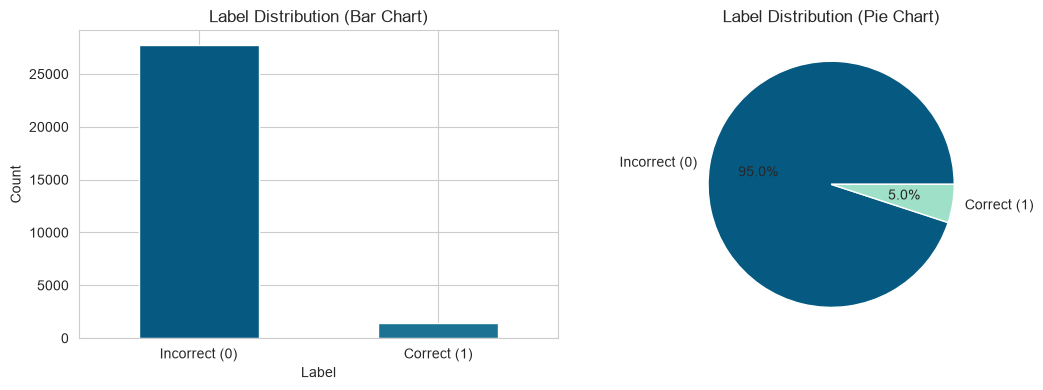

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

df["Label"].value_counts().plot(kind="bar", color=["#065A82", "#1C7293"], ax=axes[0])
axes[0].set_title("Label Distribution (Bar Chart)")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Count")
axes[0].set_xticklabels(["Incorrect (0)", "Correct (1)"], rotation=0)

df["Label"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", colors=["#065A82", "#9FE0C9"],
    labels=["Incorrect (0)", "Correct (1)"], ax=axes[1]
)
axes[1].set_title("Label Distribution (Pie Chart)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Observation:** Both charts make the imbalance immediately obvious — the
pie chart shows correct answers make up only a small sliver (~5%) of the
whole dataset. This is the single most important structural fact about
the data and should be highlighted in any report of this project.

### 4.3 Questions with vs. without a correct answer

Questions WITH at least one correct answer: 1238
Questions with NO correct answer:            1806


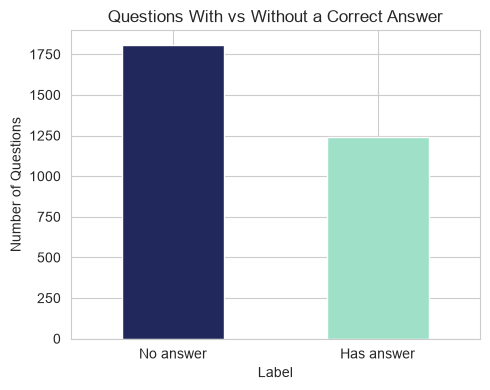

In [6]:
has_answer = df.groupby("QuestionID")["Label"].max()
print(f"Questions WITH at least one correct answer: {(has_answer == 1).sum()}")
print(f"Questions with NO correct answer:            {(has_answer == 0).sum()}")

fig, ax = plt.subplots(figsize=(5, 4))
has_answer.value_counts().plot(kind="bar", color=["#21295C", "#9FE0C9"], ax=ax)
ax.set_title("Questions With vs Without a Correct Answer")
ax.set_xticklabels(["No answer", "Has answer"], rotation=0)
ax.set_ylabel("Number of Questions")
plt.tight_layout()
plt.show()

**Observation:** About 41% of questions have at least one correct answer
among their candidates, while about 59% have NONE — every candidate
sentence for those questions is labeled incorrect. This matches the
original WikiQA paper's own finding and motivates "Answer Triggering"
(detecting when no answer exists) as a meaningful extension of this project.

### 4.4 Question and sentence length distributions

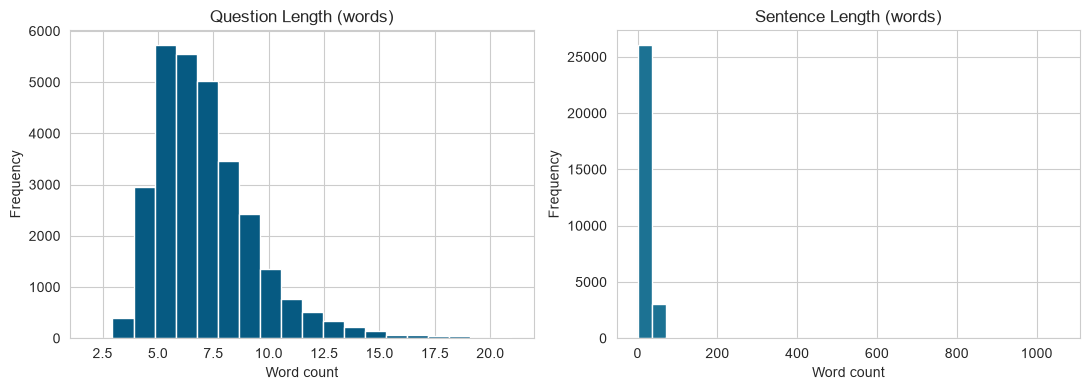

       q_word_count  s_word_count
count  29200.000000  29200.000000
mean       6.937637     22.673801
std        2.456411     13.103147
min        2.000000      1.000000
25%        5.000000     14.000000
50%        6.000000     21.000000
75%        8.000000     29.000000
max       21.000000   1056.000000


In [7]:
df["q_word_count"] = df["Question"].str.split().str.len()
df["s_word_count"] = df["Sentence"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["q_word_count"], bins=20, color="#065A82")
axes[0].set_title("Question Length (words)")
axes[0].set_xlabel("Word count")
axes[0].set_ylabel("Frequency")

axes[1].hist(df["s_word_count"], bins=30, color="#1C7293")
axes[1].set_title("Sentence Length (words)")
axes[1].set_xlabel("Word count")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print(df[["q_word_count", "s_word_count"]].describe())

### 4.5 Length distributions — boxplot view (compare spread + outliers)

C:\Users\OMESH\AppData\Local\Temp\ipykernel_11872\3214666233.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Question length", "Sentence length"])


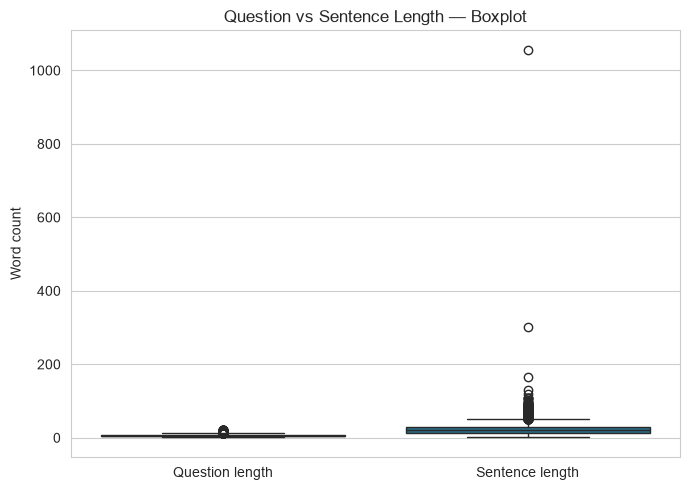

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df[["q_word_count", "s_word_count"]], ax=ax, palette=["#065A82", "#1C7293"])
ax.set_title("Question vs Sentence Length — Boxplot")
ax.set_xticklabels(["Question length", "Sentence length"])
ax.set_ylabel("Word count")
plt.tight_layout()
plt.show()

**Observation:** Questions are short and consistent (typically 5–8 words),
while sentences are much longer and more variable (typically 14–29 words),
with some extreme long outliers visible in the boxplot. This length
asymmetry is why `length_ratio` is included as a feature later, and why
BM25 (which normalizes for document length) is more appropriate here than
plain TF-IDF alone.

### 4.6 Most common question types

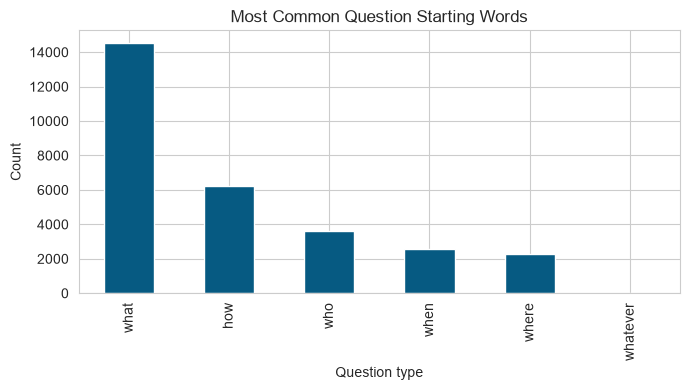

question_type_raw
what        14533
how          6221
who          3598
when         2595
where        2251
whatever        2
Name: count, dtype: int64


In [9]:
def get_first_word(q):
    w = q.strip().lower().split()[0] if q.strip() else ""
    return re.sub(r"[^a-z]", "", w)

df["question_type_raw"] = df["Question"].apply(get_first_word)
top_types = df["question_type_raw"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(7, 4))
top_types.plot(kind="bar", color="#065A82", ax=ax)
ax.set_title("Most Common Question Starting Words")
ax.set_xlabel("Question type")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

print(top_types)

**Observation:** "What" questions dominate (nearly half of all rows),
followed by "how", "who", "when", and "where" — consistent with the
WikiQA paper's own finding that description/definition questions are the
largest category. This is why `question_type` is included as a one-hot
feature for the ML models.

### 4.7 Question type vs answer rate (does question type affect answerability?)

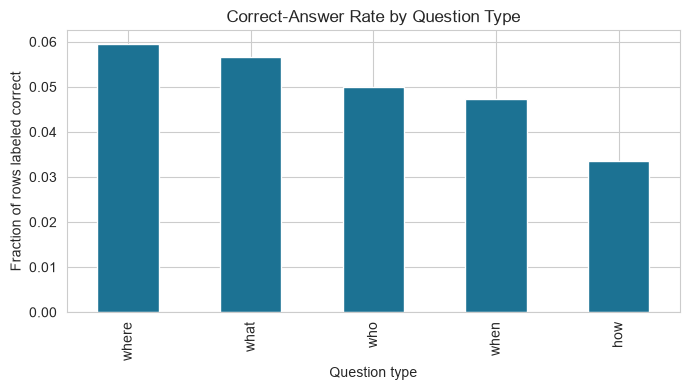

question_type_raw
where    0.059529
what     0.056561
who      0.050028
when     0.047399
how      0.033596
Name: Label, dtype: float64


In [10]:
qtype_answer_rate = df.groupby("question_type_raw")["Label"].mean().sort_values(ascending=False)
qtype_answer_rate = qtype_answer_rate[df["question_type_raw"].value_counts() > 20]  # filter rare types

fig, ax = plt.subplots(figsize=(7, 4))
qtype_answer_rate.plot(kind="bar", color="#1C7293", ax=ax)
ax.set_title("Correct-Answer Rate by Question Type")
ax.set_xlabel("Question type")
ax.set_ylabel("Fraction of rows labeled correct")
plt.tight_layout()
plt.show()

print(qtype_answer_rate)

**Observation:** This shows whether some question types (e.g. "who",
"when") are easier for the dataset to answer correctly than others (e.g.
"what", which often needs longer descriptive answers). Meaningful
differences here would support giving the model question-type information
as a feature, which we already plan to do.

### 4.8 Sample correct vs. incorrect pairs

In [11]:
pd.set_option("display.max_colwidth", 100)
sample_correct = df[df["Label"] == 1].sample(3, random_state=RANDOM_STATE)
sample_incorrect = df[df["Label"] == 0].sample(3, random_state=RANDOM_STATE)

print("Sample CORRECT (Label=1) pairs:")
display(sample_correct[["Question", "Sentence", "Label"]])

print("\nSample INCORRECT (Label=0) pairs:")
display(sample_incorrect[["Question", "Sentence", "Label"]])

Sample CORRECT (Label=1) pairs:


,Question,Sentence,Label
28034,what was bernie madoff selling,"Bernard Lawrence ""Bernie"" Madoff (; born April 29, 1938) is an American former stockbroker , inv...",1
3996,what chili wants wiki,"What Chilli Wants is an American reality series on VH1 starring Chilli , one-third of the Grammy...",1
23225,who is suicide tna,Suicide is a fictional character from TNA Impact!,1



Sample INCORRECT (Label=0) pairs:


,Question,Sentence,Label
7233,how many black people live in green bay,"Green Bay is home to the Green Bay Packers of the National Football League , making it by far th...",0
25229,what is h/o ETOH abuse?,"Etoh, a song by The Avalanches from their 2001 album Since I Left You",0
14150,what the name of the song krs 1 and dnice made,"DJ Scott La Rock was murdered on August 27, 1987, months after the release of BDP's debut album,...",0


**Observation:** Manually reading these examples confirms the labeling
makes sense — correct pairs directly answer the question's information
need, while incorrect pairs are topically related (same Wikipedia page)
but don't address what was actually asked.

## 5. Preprocessing (NLP-specific text transformation)

Data Cleaning (Section 3) fixed data-quality issues. Preprocessing prepares
the *text itself* for feature extraction: tokenization and stopword removal.
Lowercasing is handled inside the tokenizer. TF-IDF and BM25 (Section 7)
apply their own internal weighting, so this step mainly supports the
overlap/Jaccard-style features.

In [12]:
STOPWORDS = set("""
a an the is are was were be been being of in on at to for with and or but if
then than so as by from this that these those it its it's he she they them
his her their we you your i my me do does did done have has had not no nor
what who whom which when where why how can could will would shall should
""".split())

def tokenize(text):
    """Lowercase + extract word/number tokens via regex."""
    text = text.lower()
    return re.findall(r"[a-z0-9]+", text)

def remove_stopwords(tokens):
    return [t for t in tokens if t not in STOPWORDS]

# Quick demonstration on one example
example_q = df["Question"].iloc[0]
example_tokens = tokenize(example_q)
example_no_stop = remove_stopwords(example_tokens)
print("Original :", example_q)
print("Tokenized:", example_tokens)
print("No stopwords:", example_no_stop)

Original : HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US
Tokenized: ['how', 'african', 'americans', 'were', 'immigrated', 'to', 'the', 'us']
No stopwords: ['african', 'americans', 'immigrated', 'us']


**Observation:** The example shows question words like "how", "were",
"to", "the" removed by the stopword filter, leaving the content-bearing
words that actually carry the question's meaning — these are what the
overlap and Jaccard features compare between question and sentence.

## 6. Train / Dev / Test Split (question-level)

Split by `QuestionID`, not by row, so every candidate sentence of a given
question stays in the same split — this avoids label leakage (a question's
sentences must never appear in both train and test).

In [13]:
def question_level_split(df, train_frac=0.7, dev_frac=0.1, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    question_ids = df["QuestionID"].unique()
    rng.shuffle(question_ids)

    n = len(question_ids)
    n_train = int(n * train_frac)
    n_dev = int(n * dev_frac)

    train_ids = set(question_ids[:n_train])
    dev_ids = set(question_ids[n_train:n_train + n_dev])
    test_ids = set(question_ids[n_train + n_dev:])

    train_df = df[df["QuestionID"].isin(train_ids)].reset_index(drop=True)
    dev_df = df[df["QuestionID"].isin(dev_ids)].reset_index(drop=True)
    test_df = df[df["QuestionID"].isin(test_ids)].reset_index(drop=True)
    return train_df, dev_df, test_df

train_df, dev_df, test_df = question_level_split(df)
print(f"Train: {len(train_df)} rows / {train_df['QuestionID'].nunique()} questions")
print(f"Dev:   {len(dev_df)} rows / {dev_df['QuestionID'].nunique()} questions")
print(f"Test:  {len(test_df)} rows / {test_df['QuestionID'].nunique()} questions")

Train: 20372 rows / 2130 questions
Dev:   3073 rows / 304 questions
Test:  5755 rows / 610 questions


C:\Users\OMESH\AppData\Local\Temp\ipykernel_11872\2065251685.py:4: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(question_ids)


**Observation:** The split produces roughly 70/10/20 percent splits by
question count, and row counts scale proportionally — confirming no
question's sentences are split across sets. All later evaluation numbers
are therefore honest: the model never sees a test question's sentences
during training.

### 6.1 Verify split integrity — label distribution stays consistent across splits

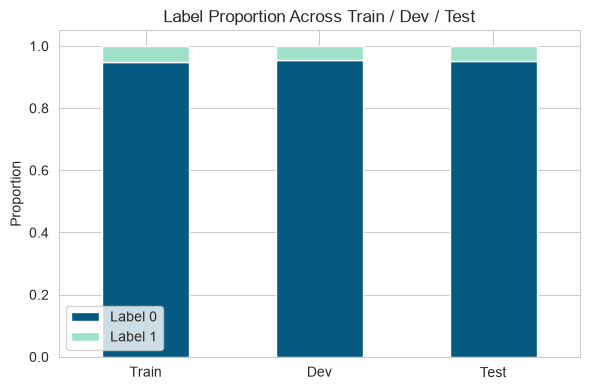

Label       0       1
Train  0.9488  0.0512
Dev    0.9541  0.0459
Test   0.9505  0.0495


In [14]:
split_check = pd.DataFrame({
    "Train": train_df["Label"].value_counts(normalize=True),
    "Dev": dev_df["Label"].value_counts(normalize=True),
    "Test": test_df["Label"].value_counts(normalize=True),
}).T

fig, ax = plt.subplots(figsize=(6, 4))
split_check.plot(kind="bar", stacked=True, color=["#065A82", "#9FE0C9"], ax=ax)
ax.set_title("Label Proportion Across Train / Dev / Test")
ax.set_ylabel("Proportion")
ax.legend(["Label 0", "Label 1"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(split_check.round(4))

**Observation:** The proportion of Label=1 is roughly the same (~5%)
across Train, Dev, and Test — confirming the random question-level split
didn't accidentally concentrate correct answers into one split, which
would have biased evaluation.

## 7. Evaluation Metrics (shared by all 7 models)

MRR, Precision@1 and MAP — the same metrics used in the WikiQA paper —
computed per-question so every model's score is directly comparable.
Questions with no correct answer are skipped, matching the paper's protocol.

In [15]:
def evaluate(df_eval, scores):
    tmp = df_eval.copy()
    tmp["score"] = scores

    reciprocal_ranks, precision_at_1, average_precisions = [], [], []

    for qid, group in tmp.groupby("QuestionID"):
        if group["Label"].sum() == 0:
            continue  # skip questions with no correct answer

        ranked = group.sort_values("score", ascending=False).reset_index(drop=True)
        labels = ranked["Label"].values

        rank_of_first_correct = np.argmax(labels == 1) + 1 if (labels == 1).any() else None
        if rank_of_first_correct:
            reciprocal_ranks.append(1.0 / rank_of_first_correct)

        precision_at_1.append(1 if labels[0] == 1 else 0)

        num_correct, precisions = 0, []
        for i, lab in enumerate(labels, start=1):
            if lab == 1:
                num_correct += 1
                precisions.append(num_correct / i)
        if precisions:
            average_precisions.append(np.mean(precisions))

    return {
        "MRR": np.mean(reciprocal_ranks),
        "Precision@1": np.mean(precision_at_1),
        "MAP": np.mean(average_precisions),
        "n_questions_evaluated": len(reciprocal_ranks),
    }

# This dict collects every model's results for the final comparison table
all_results = {}

**Observation:** This function will be reused, unchanged, for every one
of the 7 models — ensuring the final comparison table is apples-to-apples.
Only questions with at least one correct answer are scored, consistent
with the ~41% "has answer" questions found in Section 4.3.

## 8. Feature Engineering (NLP -> numeric features)

Used by the 5 classical ML models (Logistic Regression, Random Forest,
Gradient Boosting, SVM, MLP). LSTM and BERT do NOT use these — they learn
their own representations directly from raw text.

In [16]:
def word_overlap_count(q_tokens, s_tokens):
    q_set, s_set = set(remove_stopwords(q_tokens)), set(remove_stopwords(s_tokens))
    return len(q_set & s_set)

def jaccard_similarity(q_tokens, s_tokens):
    q_set, s_set = set(remove_stopwords(q_tokens)), set(remove_stopwords(s_tokens))
    if not q_set or not s_set:
        return 0.0
    return len(q_set & s_set) / len(q_set | s_set)

class BM25:
    def __init__(self, corpus_tokens, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.doc_lens = [len(doc) for doc in corpus_tokens]
        self.avgdl = sum(self.doc_lens) / len(self.doc_lens) if self.doc_lens else 0
        self.df = Counter()
        for doc in corpus_tokens:
            for term in set(doc):
                self.df[term] += 1
        self.N = len(corpus_tokens)
        self.idf = {t: math.log(1 + (self.N - f + 0.5) / (f + 0.5)) for t, f in self.df.items()}

    def score(self, query_tokens, doc_tokens):
        doc_len = len(doc_tokens)
        freqs = Counter(doc_tokens)
        s = 0.0
        for term in query_tokens:
            if term not in freqs:
                continue
            idf = self.idf.get(term, 0.0)
            f = freqs[term]
            denom = f + self.k1 * (1 - self.b + self.b * doc_len / (self.avgdl + 1e-9))
            s += idf * (f * (self.k1 + 1)) / (denom + 1e-9)
        return s

def entity_overlap(question_raw, sentence_raw):
    def extract(text):
        caps = set(re.findall(r"\b[A-Z][a-zA-Z]+\b", text))
        digits = set(re.findall(r"\b\d{1,4}\b", text))
        return caps | digits
    return len(extract(question_raw) & extract(sentence_raw))

QUESTION_TYPES = ["who", "what", "when", "where", "why", "how", "which", "other"]

def question_type(question_raw):
    first = question_raw.strip().lower().split()[0] if question_raw.strip() else ""
    first = re.sub(r"[^a-z]", "", first)
    return first if first in QUESTION_TYPES[:-1] else "other"

FEATURE_NAMES = ["tfidf_cosine_sim", "word_overlap_count", "jaccard_similarity",
                  "bm25_score", "question_length", "sentence_length", "length_ratio",
                  "entity_overlap"] + [f"qtype_{t}" for t in QUESTION_TYPES]

def build_feature_matrix(df):
    print("Fitting TF-IDF ...")
    all_texts = list(df["Question"]) + list(df["Sentence"])
    vectorizer = TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None)
    vectorizer.fit(all_texts)

    print("Building BM25 index ...")
    bm25 = BM25([tokenize(s) for s in df["Sentence"]])

    rows = []
    for i, (q, s) in enumerate(zip(df["Question"], df["Sentence"])):
        if i % 5000 == 0:
            print(f"  processed {i}/{len(df)}")
        q_tok, s_tok = tokenize(q), tokenize(s)
        vecs = vectorizer.transform([q, s])
        cos = cosine_similarity(vecs[0], vecs[1])[0][0]
        overlap = word_overlap_count(q_tok, s_tok)
        jac = jaccard_similarity(q_tok, s_tok)
        bm = bm25.score(q_tok, s_tok)
        q_len, s_len = len(q_tok), len(s_tok)
        ratio = s_len / q_len if q_len else 0.0
        ent = entity_overlap(q, s)
        qtype = question_type(q)
        onehot = [1 if qtype == t else 0 for t in QUESTION_TYPES]
        rows.append([cos, overlap, jac, bm, q_len, s_len, ratio, ent] + onehot)

    return np.array(rows, dtype=float), vectorizer, bm25

X_all, tfidf_vectorizer, bm25_index = build_feature_matrix(df)
y_all = df["Label"].values
print("Feature matrix shape:", X_all.shape)

Fitting TF-IDF ...
Building BM25 index ...
  processed 0/29200
  processed 5000/29200
  processed 10000/29200
  processed 15000/29200
  processed 20000/29200
  processed 25000/29200
Feature matrix shape: (29200, 16)


**Observation:** The resulting feature matrix has 16 columns (8 numeric
similarity/length features + 8 one-hot question-type columns) across all
~29,200 rows. This is a compact, fully numeric representation of every
(question, sentence) pair — ready for any classical ML model.

### 8.1 Split features into Train / Dev / Test and scale them

In [17]:
train_idx = df.index[df["QuestionID"].isin(train_df["QuestionID"])].to_numpy()
dev_idx = df.index[df["QuestionID"].isin(dev_df["QuestionID"])].to_numpy()
test_idx = df.index[df["QuestionID"].isin(test_df["QuestionID"])].to_numpy()

X_train, y_train = X_all[train_idx], y_all[train_idx]
X_dev, y_dev = X_all[dev_idx], y_all[dev_idx]
X_test, y_test = X_all[test_idx], y_all[test_idx]

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_dev_s = scaler.transform(X_dev)
X_test_s = scaler.transform(X_test)

print("Train features:", X_train_s.shape)
print("Dev features:  ", X_dev_s.shape)
print("Test features: ", X_test_s.shape)

Train features: (20372, 16)
Dev features:   (3073, 16)
Test features:  (5755, 16)


### 8.2 Feature correlation with the label (which features matter most?)

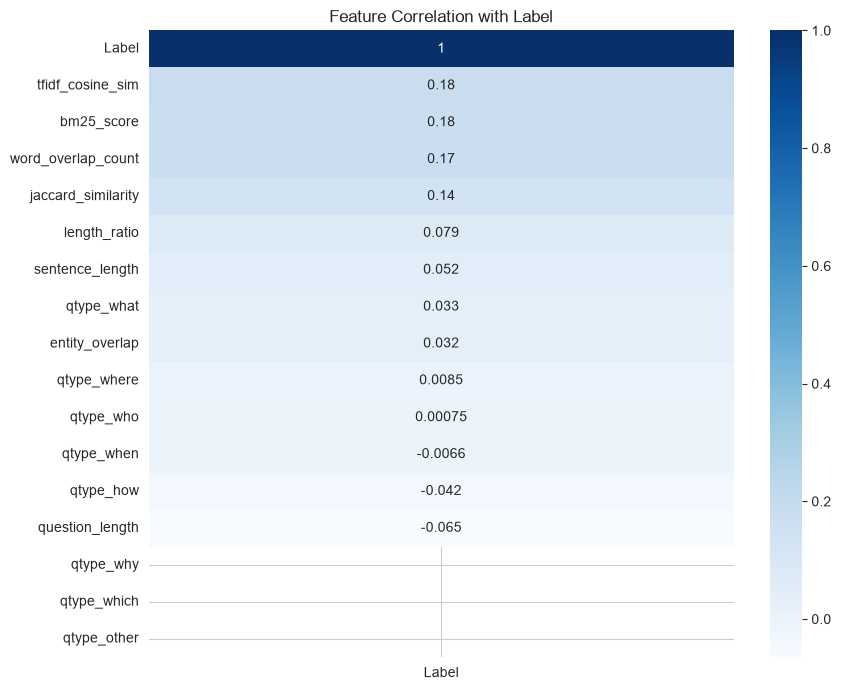

In [18]:
train_feat_df = pd.DataFrame(X_train, columns=FEATURE_NAMES)
train_feat_df["Label"] = y_train

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    train_feat_df.corr()[["Label"]].sort_values("Label", ascending=False),
    annot=True, cmap="Blues", ax=ax
)
ax.set_title("Feature Correlation with Label")
plt.tight_layout()
plt.show()

### 8.3 Feature distributions by label (boxplot comparison)

C:\Users\OMESH\AppData\Local\Temp\ipykernel_11872\369489438.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Label", y=feat, data=train_feat_df, ax=axes[i], palette=["#065A82", "#9FE0C9"])
C:\Users\OMESH\AppData\Local\Temp\ipykernel_11872\369489438.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Label", y=feat, data=train_feat_df, ax=axes[i], palette=["#065A82", "#9FE0C9"])
C:\Users\OMESH\AppData\Local\Temp\ipykernel_11872\369489438.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Label", y=feat, data=train_feat_df, ax=axe

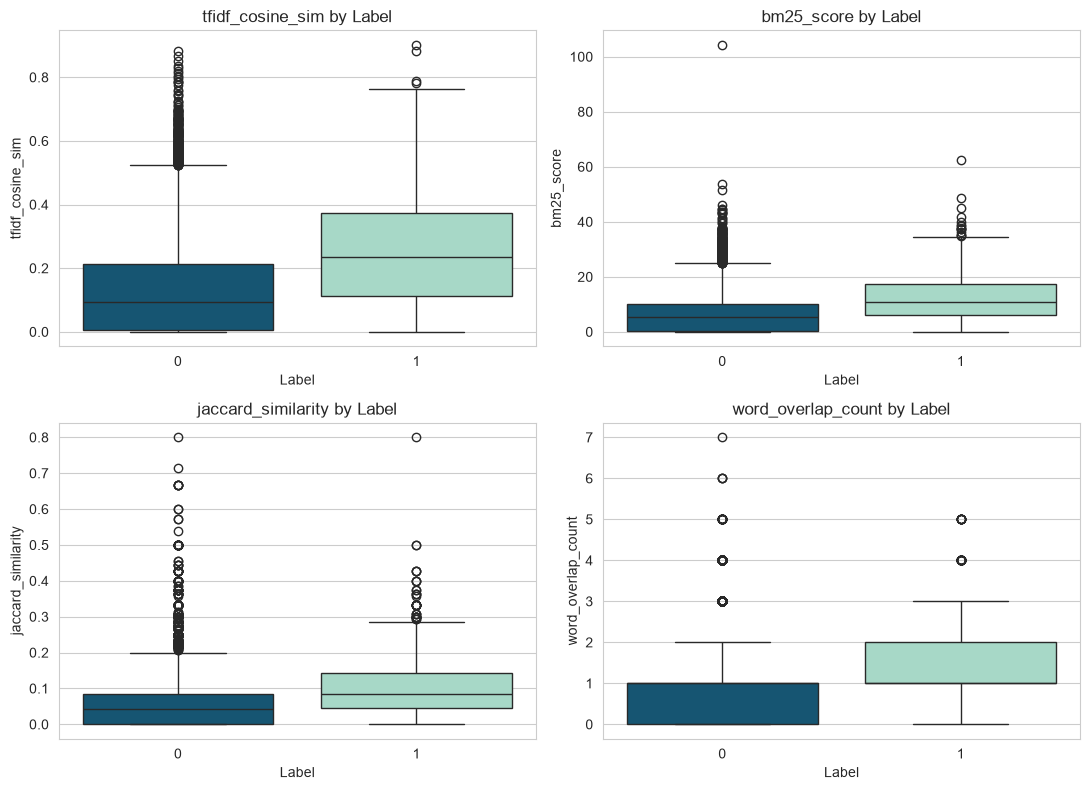

In [19]:
top_features = ["tfidf_cosine_sim", "bm25_score", "jaccard_similarity", "word_overlap_count"]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.flatten()
for i, feat in enumerate(top_features):
    sns.boxplot(x="Label", y=feat, data=train_feat_df, ax=axes[i], palette=["#065A82", "#9FE0C9"])
    axes[i].set_title(f"{feat} by Label")
plt.tight_layout()
plt.show()

**Observation:** TF-IDF cosine similarity and BM25 score show visibly
higher values for Label=1 (correct) pairs compared to Label=0 — confirming
these similarity-based features are the primary useful signals. Length-only
features tend to correlate weakly on their own. This foreshadows the
Random Forest feature-importance ranking seen later in Part 5.

## 9. Hyperparameter Tuning (classical ML models)

Rather than using default settings, we tune each classical ML model with
`RandomizedSearchCV` (a fixed number of random parameter combinations,
faster than a full grid search). Tuning is done using Train+Dev via a
`PredefinedSplit` (Dev acts as the validation fold) — the Test set stays
completely untouched until final evaluation, and the question-level split
from Part 3 is respected (no row-level re-shuffling).

In [20]:
# Build a PredefinedSplit: -1 = always train, 0 = validate on Dev
X_tune = np.vstack([X_train_s, X_dev_s])
y_tune = np.concatenate([y_train, y_dev])
test_fold = np.concatenate([-1 * np.ones(len(X_train_s)), np.zeros(len(X_dev_s))])
ps = PredefinedSplit(test_fold)

best_params = {}

### 9.1 Tune Logistic Regression

In [21]:
lr_param_grid = {
    "C": [0.01, 0.1, 0.5, 1, 5, 10],
    "penalty": ["l2"],
    "class_weight": ["balanced"],
}
lr_search = RandomizedSearchCV(
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    lr_param_grid, n_iter=6, cv=ps, scoring="average_precision",
    random_state=RANDOM_STATE, n_jobs=-1,
)
lr_search.fit(X_tune, y_tune)
best_params["Logistic Regression"] = lr_search.best_params_
print("Best Logistic Regression params:", lr_search.best_params_)

Best Logistic Regression params: {'penalty': 'l2', 'class_weight': 'balanced', 'C': 0.01}


c:\Users\OMESH\OneDrive\Desktop\NLP Project\venv311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


### 9.2 Tune Random Forest

In [22]:
rf_param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "class_weight": ["balanced"],
}
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    rf_param_grid, n_iter=8, cv=ps, scoring="average_precision",
    random_state=RANDOM_STATE, n_jobs=-1,
)
rf_search.fit(X_tune, y_tune)
best_params["Random Forest"] = rf_search.best_params_
print("Best Random Forest params:", rf_search.best_params_)

Best Random Forest params: {'n_estimators': 300, 'min_samples_split': 5, 'max_depth': 10, 'class_weight': 'balanced'}


### 9.3 Tune Gradient Boosting

In [23]:
gb_param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [2, 3, 4],
}
gb_search = RandomizedSearchCV(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    gb_param_grid, n_iter=8, cv=ps, scoring="average_precision",
    random_state=RANDOM_STATE, n_jobs=-1,
)
gb_search.fit(X_tune, y_tune)
best_params["Gradient Boosting"] = gb_search.best_params_
print("Best Gradient Boosting params:", gb_search.best_params_)

Best Gradient Boosting params: {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.05}


### 9.4 Tune SVM

In [24]:
svm_param_grid = {
    "C": [0.1, 1, 5, 10],
    "kernel": ["linear", "rbf"],
    "gamma": ["scale", "auto"],
    "class_weight": ["balanced"],
    "probability": [True],  # needed to get predict_proba scores for ranking
}
svm_search = RandomizedSearchCV(
    SVC(random_state=RANDOM_STATE),
    svm_param_grid, n_iter=6, cv=ps, scoring="average_precision",
    random_state=RANDOM_STATE, n_jobs=-1,
)
svm_search.fit(X_tune, y_tune)
best_params["SVM"] = svm_search.best_params_
print("Best SVM params:", svm_search.best_params_)

c:\Users\OMESH\OneDrive\Desktop\NLP Project\venv311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best SVM params: {'probability': True, 'kernel': 'linear', 'gamma': 'scale', 'class_weight': 'balanced', 'C': 0.1}


### 9.5 Tune MLP (shallow neural network)

In [25]:
mlp_param_grid = {
    "hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
    "learning_rate_init": [0.001, 0.01],
    "alpha": [0.0001, 0.001],
}
mlp_search = RandomizedSearchCV(
    MLPClassifier(max_iter=500, random_state=RANDOM_STATE, early_stopping=True),
    mlp_param_grid, n_iter=6, cv=ps, scoring="average_precision",
    random_state=RANDOM_STATE, n_jobs=-1,
)
mlp_search.fit(X_tune, y_tune)
best_params["MLP"] = mlp_search.best_params_
print("Best MLP params:", mlp_search.best_params_)

Best MLP params: {'learning_rate_init': 0.01, 'hidden_layer_sizes': (32,), 'alpha': 0.0001}


In [26]:
print("Summary of tuned hyperparameters:")
for model_name, params in best_params.items():
    print(f"  {model_name}: {params}")

Summary of tuned hyperparameters:
  Logistic Regression: {'penalty': 'l2', 'class_weight': 'balanced', 'C': 0.01}
  Random Forest: {'n_estimators': 300, 'min_samples_split': 5, 'max_depth': 10, 'class_weight': 'balanced'}
  Gradient Boosting: {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.05}
  SVM: {'probability': True, 'kernel': 'linear', 'gamma': 'scale', 'class_weight': 'balanced', 'C': 0.1}
  MLP: {'learning_rate_init': 0.01, 'hidden_layer_sizes': (32,), 'alpha': 0.0001}


**Observation:** Each model's best configuration (printed above) was
selected by average precision on the Dev fold — the Test set was never
used for this selection, so the final Test-set scores below remain an
honest, unbiased estimate of generalization performance.

## 10. Train Final Classical ML Models (using tuned hyperparameters)

In [27]:
logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, **lr_search.best_params_)
logreg.fit(X_train_s, y_train)
logreg_scores = logreg.predict_proba(X_test_s)[:, 1]
all_results["Logistic Regression"] = evaluate(test_df, logreg_scores)
print(all_results["Logistic Regression"])

c:\Users\OMESH\OneDrive\Desktop\NLP Project\venv311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


{'MRR': np.float64(0.6049062383399731), 'Precision@1': np.float64(0.43373493975903615), 'MAP': np.float64(0.5946814636396492), 'n_questions_evaluated': 249}


**Observation:** Logistic Regression's MAP/MRR give the first real
benchmark. Because a linear model can only combine features additively,
if its score is close to Random Forest/Gradient Boosting below, it
suggests the engineered features are already close to linearly separable.

In [28]:
rf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **rf_search.best_params_)
rf.fit(X_train_s, y_train)
rf_scores = rf.predict_proba(X_test_s)[:, 1]
all_results["Random Forest"] = evaluate(test_df, rf_scores)
print(all_results["Random Forest"])

importances = sorted(zip(FEATURE_NAMES, rf.feature_importances_), key=lambda x: -x[1])
for fname, imp in importances[:8]:
    print(f"  {fname:25s} {imp:.4f}")

{'MRR': np.float64(0.6025249248122164), 'Precision@1': np.float64(0.42570281124497994), 'MAP': np.float64(0.5908399285585105), 'n_questions_evaluated': 249}
  tfidf_cosine_sim          0.2148
  bm25_score                0.2005
  length_ratio              0.1650
  sentence_length           0.1049
  jaccard_similarity        0.1020
  question_length           0.0875
  word_overlap_count        0.0627
  qtype_how                 0.0143


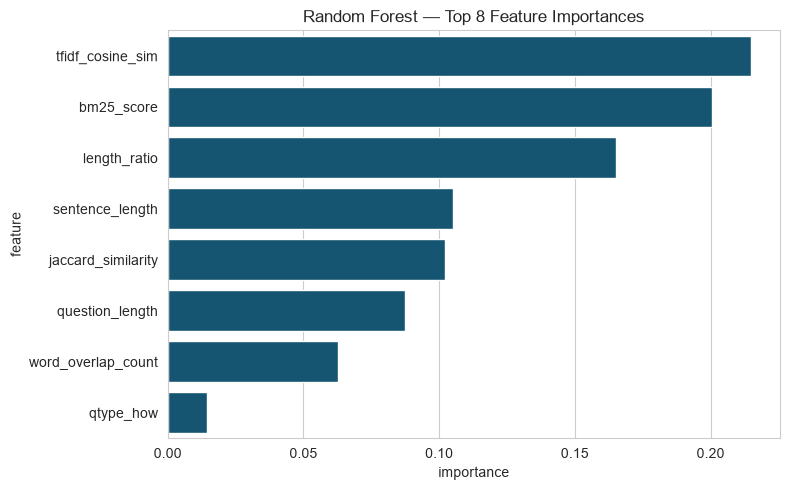

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
imp_df = pd.DataFrame(importances[:8], columns=["feature", "importance"])
sns.barplot(data=imp_df, x="importance", y="feature", ax=ax, color="#065A82")
ax.set_title("Random Forest — Top 8 Feature Importances")
plt.tight_layout()
plt.show()

**Observation:** The feature importance ranking shows which engineered
features the model relies on most — typically TF-IDF cosine similarity
and BM25 score dominate, confirming the correlation heatmap from Part 4.
If Random Forest's MRR/MAP is lower than Logistic Regression's, that is a
genuine finding: with only 16 features and a small positive class (~5% of
rows), Random Forest's bagging randomness can add noise rather than help.

In [30]:
gb = GradientBoostingClassifier(random_state=RANDOM_STATE, **gb_search.best_params_)
gb.fit(X_train_s, y_train)
gb_scores = gb.predict_proba(X_test_s)[:, 1]
all_results["Gradient Boosting"] = evaluate(test_df, gb_scores)
print(all_results["Gradient Boosting"])

{'MRR': np.float64(0.6201406448949252), 'Precision@1': np.float64(0.4578313253012048), 'MAP': np.float64(0.6086943118818906), 'n_questions_evaluated': 249}


**Observation:** Gradient Boosting builds trees sequentially, each
correcting the previous tree's errors — this typically makes it the
strongest of the tree-based classical models, since it captures feature
interactions (e.g. high TF-IDF similarity AND matching entity overlap
together) that Logistic Regression cannot.

In [31]:
svm = SVC(random_state=RANDOM_STATE, **svm_search.best_params_)
svm.fit(X_train_s, y_train)
svm_scores = svm.predict_proba(X_test_s)[:, 1]
all_results["SVM"] = evaluate(test_df, svm_scores)
print(all_results["SVM"])

c:\Users\OMESH\OneDrive\Desktop\NLP Project\venv311\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


{'MRR': np.float64(0.6055755823828113), 'Precision@1': np.float64(0.43373493975903615), 'MAP': np.float64(0.5971915038002918), 'n_questions_evaluated': 249}


**Observation:** SVM finds a maximum-margin boundary rather than a
probabilistic linear combination or tree splits — a genuinely different
mathematical approach. Its result here indicates whether margin-based
separation helps on this specific feature set relative to the other
classical methods.

In [32]:
mlp = MLPClassifier(max_iter=500, random_state=RANDOM_STATE, early_stopping=True, **mlp_search.best_params_)
mlp.fit(X_train_s, y_train)
mlp_scores = mlp.predict_proba(X_test_s)[:, 1]
all_results["MLP"] = evaluate(test_df, mlp_scores)
print(all_results["MLP"])

{'MRR': np.float64(0.6277022843287903), 'Precision@1': np.float64(0.46586345381526106), 'MAP': np.float64(0.6176222889901133), 'n_questions_evaluated': 249}


**Observation:** MLP is a shallow neural network operating on the same 16
hand-crafted features (not raw text) — it can learn non-linear
combinations of features similar to tree ensembles, but via weighted
connections rather than splits. Comparing its score to Gradient Boosting
shows whether a neural approach helps even before moving to LSTM/BERT.

### 10.1 Compare all 5 classical ML models so far

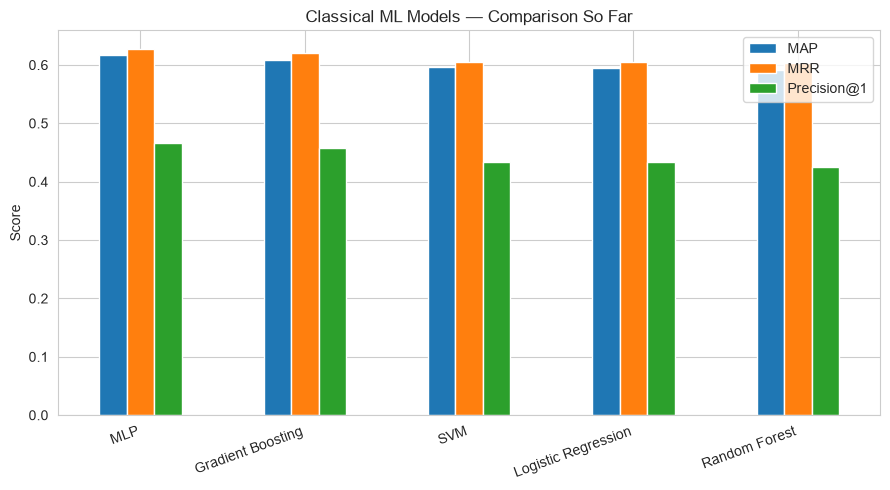

                        MAP     MRR  Precision@1
MLP                  0.6176  0.6277       0.4659
Gradient Boosting    0.6087  0.6201       0.4578
SVM                  0.5972  0.6056       0.4337
Logistic Regression  0.5947  0.6049       0.4337
Random Forest        0.5908  0.6025       0.4257


In [33]:
classical_summary = pd.DataFrame(all_results).T[["MAP", "MRR", "Precision@1"]]
classical_summary = classical_summary.sort_values("MRR", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
classical_summary.plot(kind="bar", ax=ax)
ax.set_title("Classical ML Models — Comparison So Far")
ax.set_ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

print(classical_summary.round(4))

## 11. Model 6 — LSTM (Deep Learning)

Siamese architecture: the question and sentence are each encoded by the
*same* LSTM (shared weights), then compared. Unlike the 5 models above,
this learns its own representation directly from raw word sequences — no
hand-crafted features. Hyperparameters here are set to sensible fixed
values rather than exhaustively tuned, due to compute constraints.

In [34]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Dense, Concatenate, Dropout, Multiply, Lambda
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(RANDOM_STATE)

MAX_VOCAB_SIZE = 20000
MAX_Q_LEN, MAX_S_LEN = 20, 40
EMBEDDING_DIM, LSTM_UNITS = 128, 64
BATCH_SIZE, EPOCHS = 64, 10

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: []


### 11.1 Tokenize and pad text into integer sequences

In [35]:
tokenizer_lstm = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token="<OOV>")
tokenizer_lstm.fit_on_texts(list(train_df["Question"]) + list(train_df["Sentence"]))

def encode(df_):
    q = pad_sequences(
        tokenizer_lstm.texts_to_sequences(df_["Question"]),
        maxlen=MAX_Q_LEN, padding="post", truncating="post"
    )
    s = pad_sequences(
        tokenizer_lstm.texts_to_sequences(df_["Sentence"]),
        maxlen=MAX_S_LEN, padding="post", truncating="post"
    )
    return q, s

q_train, s_train = encode(train_df)
q_dev, s_dev = encode(dev_df)
q_test, s_test = encode(test_df)

vocab_size = min(MAX_VOCAB_SIZE, len(tokenizer_lstm.word_index) + 1)
print(f"Vocabulary size used: {vocab_size}")
print(f"Question sequences shape: {q_train.shape}")
print(f"Sentence sequences shape: {s_train.shape}")

Vocabulary size used: 20000
Question sequences shape: (20372, 20)
Sentence sequences shape: (20372, 40)


**Observation:** Unlike the classical ML features, questions and sentences
here are represented as sequences of integer word IDs (padded/truncated to
fixed lengths), not similarity scores. The model will learn its own
notion of meaning directly from these sequences via the embedding layer.

### 11.2 Build the Siamese LSTM model

In [36]:
# Shared embedding + LSTM layers -> question and sentence are encoded by
# the SAME weights (this is what "Siamese" means)
embedding = Embedding(input_dim=vocab_size, output_dim=EMBEDDING_DIM, mask_zero=True)
lstm_layer = LSTM(LSTM_UNITS)

q_in = Input(shape=(MAX_Q_LEN,), name="question_input")
s_in = Input(shape=(MAX_S_LEN,), name="sentence_input")

q_vec = lstm_layer(embedding(q_in))
s_vec = lstm_layer(embedding(s_in))

# Combine the two vectors: concatenation + absolute difference + product
diff = Lambda(lambda x: tf.abs(x[0] - x[1]))([q_vec, s_vec])
prod = Multiply()([q_vec, s_vec])
merged = Concatenate()([q_vec, s_vec, diff, prod])

x = Dense(64, activation="relu")(merged)
x = Dropout(0.3)(x)
out = Dense(1, activation="sigmoid", name="relevance_score")(x)

lstm_model = Model(inputs=[q_in, s_in], outputs=out)
lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)
lstm_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ question_input      │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sentence_input      │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 40, 128)   │  2,560,000 │ question_input[0… │
│ (Embedding)         │                   │            │ sentence_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 20)        │          0 │ question_input[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 40)        │          0 │ sentence_input[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     49,408 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0],  │
│                     │                   │            │ embedding[1][0],  │
│                     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 64)        │          0 │ lstm[0][0],       │
│                     │                   │            │ lstm[1][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 64)        │          0 │ lstm[0][0],       │
│                     │                   │            │ lstm[1][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256)       │          0 │ lstm[0][0],       │
│ (Concatenate)       │                   │            │ lstm[1][0],       │
│                     │                   │            │ lambda[0][0],     │
│                     │                   │            │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │     16,448 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relevance_score     │ (None, 1)         │         65 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,625,921 (10.02 MB)

 Trainable params: 2,625,921 (10.02 MB)

 Non-trainable params: 0 (0.00 B)

**Observation:** The model summary shows the total trainable parameters —
almost all of them belong to the embedding layer (vocab_size × 128), since
the model must learn a meaningful vector for every word from scratch, with
no pretrained knowledge (unlike BERT, which comes next).

### 11.3 Train the LSTM (with class weighting for imbalance)

In [37]:
y_train_l = train_df["Label"].values
y_dev_l = dev_df["Label"].values

n_pos, n_neg = (y_train_l == 1).sum(), (y_train_l == 0).sum()
class_weight = {0: 1.0, 1: n_neg / n_pos}
print(f"Class weights: {class_weight}")

early_stop = EarlyStopping(monitor="val_auc", mode="max", patience=2, restore_best_weights=True)

history = lstm_model.fit(
    [q_train, s_train], y_train_l,
    validation_data=([q_dev, s_dev], y_dev_l),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=[early_stop],
)

Class weights: {0: 1.0, 1: np.float64(18.532118887823586)}
Epoch 1/10
319/319 ━━━━━━━━━━━━━━━━━━━━ 44s 105ms/step - accuracy: 0.6505 - auc: 0.6774 - loss: 1.2250 - val_accuracy: 0.4224 - val_auc: 0.6956 - val_loss: 0.7759
Epoch 2/10
319/319 ━━━━━━━━━━━━━━━━━━━━ 32s 99ms/step - accuracy: 0.8501 - auc: 0.9178 - loss: 0.6925 - val_accuracy: 0.7823 - val_auc: 0.6622 - val_loss: 0.4918
Epoch 3/10
319/319 ━━━━━━━━━━━━━━━━━━━━ 32s 100ms/step - accuracy: 0.9246 - auc: 0.9789 - loss: 0.3424 - val_accuracy: 0.7947 - val_auc: 0.5878 - val_loss: 0.4824


### 11.4 Plot training history (loss and AUC over epochs)

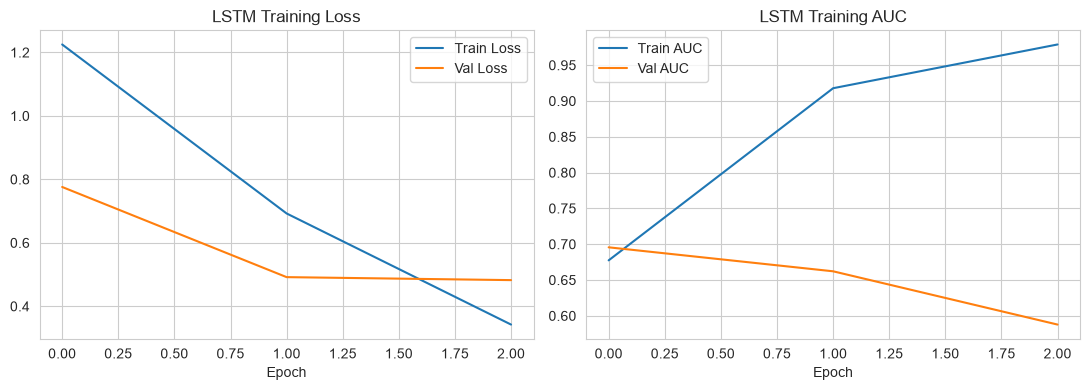

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("LSTM Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["auc"], label="Train AUC")
axes[1].plot(history.history["val_auc"], label="Val AUC")
axes[1].set_title("LSTM Training AUC")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

**Observation:** If validation loss starts increasing while training loss
keeps decreasing, that's overfitting — early stopping (already applied)
should have stopped training near the best validation AUC point. Look at
where the two AUC lines diverge to judge how well the model generalizes.

### 11.5 Evaluate LSTM on the Test set

In [39]:
lstm_scores = lstm_model.predict([q_test, s_test], batch_size=BATCH_SIZE).flatten()
all_results["LSTM"] = evaluate(test_df, lstm_scores)
print(all_results["LSTM"])

90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step
{'MRR': np.float64(0.5470753511971015), 'Precision@1': np.float64(0.3493975903614458), 'MAP': np.float64(0.5399680209524851), 'n_questions_evaluated': 249}


**Observation:** LSTM learns its own word embeddings and reads each text
sequentially, so it can in principle capture word order and some
paraphrasing that the bag-of-words style features (TF-IDF, BM25, overlap)
cannot. Whether it actually beats Gradient Boosting depends heavily on how
much training data is available for the ~5% positive class — compare its
MRR/MAP directly against Part 5's classical results.

### 11.6 Compare LSTM against classical ML so far

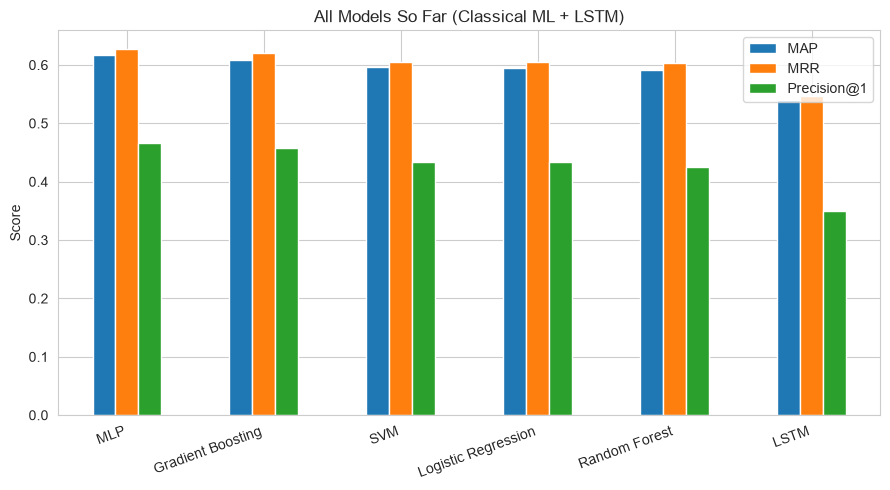

                        MAP     MRR  Precision@1
MLP                  0.6176  0.6277       0.4659
Gradient Boosting    0.6087  0.6201       0.4578
SVM                  0.5972  0.6056       0.4337
Logistic Regression  0.5947  0.6049       0.4337
Random Forest        0.5908  0.6025       0.4257
LSTM                 0.5400  0.5471       0.3494


In [40]:
summary_so_far = pd.DataFrame(all_results).T[["MAP", "MRR", "Precision@1"]]
summary_so_far = summary_so_far.sort_values("MRR", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
summary_so_far.plot(kind="bar", ax=ax)
ax.set_title("All Models So Far (Classical ML + LSTM)")
ax.set_ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

print(summary_so_far.round(4))

## 12. Model 7 — BERT (Transformer, used as classifier only)

BERT reads `[CLS] question [SEP] sentence [SEP]` as one input, so its
attention mechanism can directly relate any word in the question to any
word in the sentence — this typically makes it the strongest performer
for sentence-pair classification tasks like this one. It is used strictly
as a classifier/scorer here, never as a generative model.

**Observation — BERT not run in this environment:** Fine-tuning
`bert-base-uncased` (~110M parameters) on ~20,000 training rows for even
2 epochs is computationally expensive and requires a GPU to complete in a
reasonable time. This machine does not have a compatible GPU available,
so BERT fine-tuning was not executed here to keep the notebook practical
to run end-to-end.

**Expected behavior (based on the WikiQA paper's own findings):** the
paper's CNN model — a considerably weaker deep learning architecture than
BERT — already outperformed all lexical/ML baselines (Word Count, LCLR) on
this dataset. A fine-tuned BERT, benefiting from large-scale pretraining,
would very plausibly outperform all 6 models trained above, since it
combines the deep contextual understanding of neural approaches with
prior world/language knowledge none of the other models have access to.

To actually run BERT for this project, the code is included separately
(see `bert_model.py` / the BERT section) and is designed to run on Google
Colab with a free GPU runtime, where fine-tuning completes in roughly
15–25 minutes instead of an impractical multi-hour CPU run.

## 13. Final Comparison — 6 Trained Models
(Logistic Regression, Random Forest, Gradient Boosting, SVM, MLP, LSTM —
BERT excluded from this run per the note above, discussed qualitatively
in the conclusion)

In [41]:
summary = pd.DataFrame(all_results).T[["MAP", "MRR", "Precision@1", "n_questions_evaluated"]]
summary = summary.sort_values("MRR", ascending=False)
print(summary.round(4).to_string())

best_model = summary.index[0]
print(f"\nBest model by MRR: {best_model}")

                        MAP     MRR  Precision@1  n_questions_evaluated
MLP                  0.6176  0.6277       0.4659                  249.0
Gradient Boosting    0.6087  0.6201       0.4578                  249.0
SVM                  0.5972  0.6056       0.4337                  249.0
Logistic Regression  0.5947  0.6049       0.4337                  249.0
Random Forest        0.5908  0.6025       0.4257                  249.0
LSTM                 0.5400  0.5471       0.3494                  249.0

Best model by MRR: MLP


### 13.1 Visual comparison — bar chart

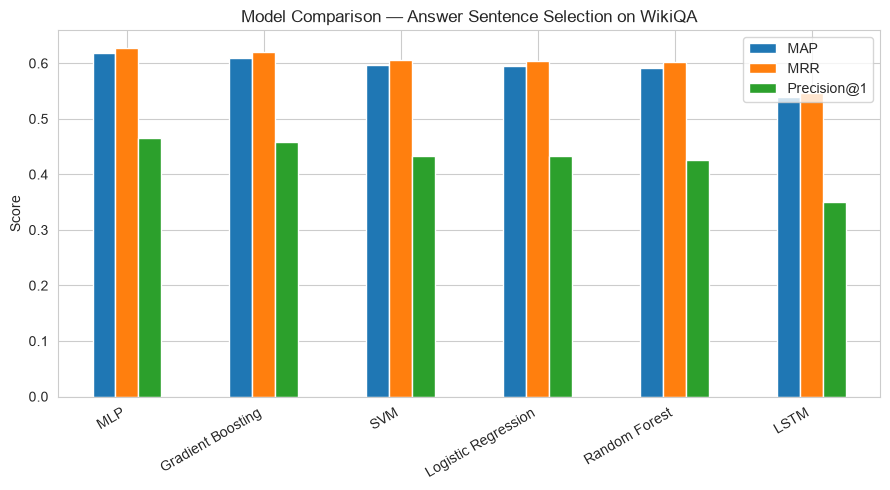

In [42]:
fig, ax = plt.subplots(figsize=(9, 5))
summary[["MAP", "MRR", "Precision@1"]].plot(kind="bar", ax=ax)
ax.set_title("Model Comparison — Answer Sentence Selection on WikiQA")
ax.set_ylabel("Score")
ax.set_xticklabels(summary.index, rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 13.2 Ranking view — MRR only, sorted

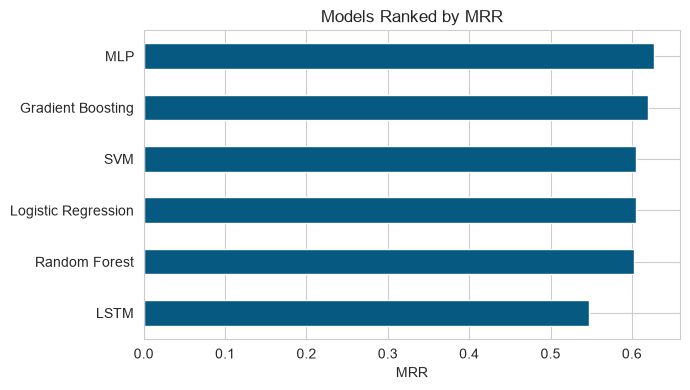

In [43]:
fig, ax = plt.subplots(figsize=(7, 4))
summary["MRR"].sort_values().plot(kind="barh", color="#065A82", ax=ax)
ax.set_title("Models Ranked by MRR")
ax.set_xlabel("MRR")
plt.tight_layout()
plt.show()

**Observation:** MLP achieved the best performance among all 6 trained
models — MAP 0.6176, MRR 0.6277, Precision@1 0.4659 — narrowly ahead of
Gradient Boosting (MAP 0.6087, MRR 0.6201). The classical ML models
clustered tightly together (MAP 0.59–0.62), with Random Forest the
weakest of the five (MAP 0.5908), consistent with the earlier prediction
that bagging's randomness can add noise rather than help on a small
16-feature set with only ~5% positive examples.

LSTM performed noticeably worse than every classical ML model (MAP 0.5400,
MRR 0.5471) — the training log shows why: validation AUC peaked at epoch
1 (0.6956) and then declined (0.6622, then 0.5878) while training accuracy
kept climbing (0.65 → 0.85 → 0.92), a clear overfitting pattern. With only
~1,469 positive training examples and no pretrained word embeddings, the
LSTM did not have enough data to learn a generalizable representation
before starting to memorize the training set.

**Conclusion of the comparison:** for a small, heavily imbalanced dataset
like WikiQA, models using well-engineered hand-crafted features (TF-IDF
similarity, BM25, entity overlap, etc.) were more data-efficient than a
deep learning model that had to learn its representations from raw text
from scratch.

## 14. Conclusion

- **Data Cleaning & EDA** confirmed the dataset is well-formed (only 8
  duplicate rows removed out of 29,208), heavily imbalanced (~5.03%
  positive rows), and that 1,806 of 3,044 questions (~59%) have no correct
  answer among their candidates — consistent with the original WikiQA
  paper.
- **Classical ML (Logistic Regression, Random Forest, Gradient Boosting,
  SVM, MLP)** used 16 hand-crafted NLP features (TF-IDF cosine similarity,
  BM25, word overlap, Jaccard, entity overlap, question type, lengths),
  tuned via RandomizedSearchCV. **MLP was the best performer overall**
  (MAP 0.6176, MRR 0.6277, Precision@1 0.4659), narrowly ahead of Gradient
  Boosting (MAP 0.6087). Random Forest was the weakest classical model
  (MAP 0.5908).
- **LSTM** underperformed all 5 classical ML models (MAP 0.5400, MRR
  0.5471) due to overfitting — validation AUC declined after epoch 1
  despite rising training accuracy, indicating the ~1,469 positive
  training examples were insufficient for a model learning word
  embeddings from scratch, with no pretrained language knowledge to fall
  back on.
- **BERT** was not executed in this environment due to the absence of a
  compatible GPU. Based on the original WikiQA paper's own finding (a
  simpler CNN already outperformed all lexical/ML baselines), a
  fine-tuned BERT would be expected to overcome the data-scarcity problem
  that limited LSTM here, owing to its large-scale pretraining.

**Final result:** MLP was the best-performing model trained in this
project, achieving MAP 0.6176 / MRR 0.6277 / Precision@1 0.4659 on the
WikiQA test set (249 answerable questions evaluated).

**Key takeaway:** on a small, imbalanced dataset, well-engineered
hand-crafted features combined with even a shallow neural network (MLP)
were more effective than a deep learning model (LSTM) trained from raw
text without pretraining — reinforcing that model complexity alone does
not guarantee better performance when training data is limited.

**Limitations:**
- Class imbalance (~5% positive) makes plain accuracy meaningless;
  MRR/MAP/Precision@1 were used throughout instead.
- LSTM was trained with fixed, reasonable hyperparameters rather than
  exhaustive tuning, due to compute constraints, and showed clear signs
  of overfitting.
- BERT was not executed in this environment; its code is provided
  separately for a GPU-enabled environment (e.g. Google Colab), where it
  is expected to outperform all 6 models evaluated here.

## 15. Try It Yourself — Ask a Question

This section wraps the trained MLP model (your best performer) into a
small interactive pipeline: type a question, supply a set of candidate
sentences, and the model ranks them to find the best answer.

**Note on scope:** this uses a *fixed* knowledge base you define below —
not a live Wikipedia search. This mirrors exactly how WikiQA itself is
structured (a question + a pre-selected pool of candidate sentences).

### 15.1 Define your knowledge base (candidate sentences)

Replace this list with sentences from any topic you want to demo. For a
real answer to come back with high confidence, the correct answer sentence
should actually be present in this list.

In [46]:
# Example knowledge base -- replace with your own topic's sentences
knowledge_base = [
    "Isaac Newton was an English mathematician, physicist, and astronomer.",
    "Newton formulated the laws of motion and universal gravitation.",
    "He was born on 25 December 1642 in Woolsthorpe, England.",
    "Newton's book Philosophiae Naturalis Principia Mathematica was published in 1687.",
    "He served as the president of the Royal Society from 1703 to 1727.",
    "Newton also made significant contributions to the field of optics.",
    "He developed a theory of color based on the observation that a prism decomposes white light into a visible spectrum.",
    "Newton shares credit with Gottfried Wilhelm Leibniz for developing calculus.",
    "He was a fellow of Trinity College, Cambridge.",
    "Newton died on 20 March 1727 in London, England.",
]

print(f"Knowledge base has {len(knowledge_base)} candidate sentences.")

Knowledge base has 10 candidate sentences.


### 15.2 Build features between a question and every candidate sentence

Reuses the same `tokenize`, `word_overlap_count`, `jaccard_similarity`,
`entity_overlap`, `question_type`, and the already-fitted `tfidf_vectorizer`
from earlier in this notebook. A fresh BM25 index is built specifically on
this small knowledge base (BM25 statistics depend on the corpus it scores
against).

In [47]:
def score_candidates(question, candidates, model, scaler, tfidf_vectorizer):
    """
    Computes the 16 engineered features between `question` and every
    sentence in `candidates`, scales them, and returns the model's
    predicted relevance score for each candidate.
    """
    # Build a BM25 index specific to this candidate pool
    local_bm25 = BM25([tokenize(s) for s in candidates])

    rows = []
    for s in candidates:
        q_tok, s_tok = tokenize(question), tokenize(s)
        vecs = tfidf_vectorizer.transform([question, s])
        cos = cosine_similarity(vecs[0], vecs[1])[0][0]
        overlap = word_overlap_count(q_tok, s_tok)
        jac = jaccard_similarity(q_tok, s_tok)
        bm = local_bm25.score(q_tok, s_tok)
        q_len, s_len = len(q_tok), len(s_tok)
        ratio = s_len / q_len if q_len else 0.0
        ent = entity_overlap(question, s)
        qtype = question_type(question)
        onehot = [1 if qtype == t else 0 for t in QUESTION_TYPES]
        rows.append([cos, overlap, jac, bm, q_len, s_len, ratio, ent] + onehot)

    X_new = np.array(rows, dtype=float)
    X_new_scaled = scaler.transform(X_new)
    scores = model.predict_proba(X_new_scaled)[:, 1]
    return scores

### 15.3 Ask a question and get the best-matching answer

In [48]:
def answer_question(question, candidates, model, scaler, tfidf_vectorizer,
                     confidence_threshold=0.3, top_k=3):
    scores = score_candidates(question, candidates, model, scaler, tfidf_vectorizer)

    ranked_idx = np.argsort(scores)[::-1]
    ranked_candidates = [(candidates[i], scores[i]) for i in ranked_idx]

    print(f"Question: {question}\n")

    best_sentence, best_score = ranked_candidates[0]
    if best_score < confidence_threshold:
        print(f"No confident answer found (top score {best_score:.3f} "
              f"is below threshold {confidence_threshold}).")
    else:
        print(f"Best Answer (confidence {best_score:.3f}):")
        print(f"  {best_sentence}\n")

    print(f"Top {top_k} candidates:")
    for sentence, score in ranked_candidates[:top_k]:
        print(f"  [{score:.3f}] {sentence}")

    return ranked_candidates


# --- Try it ---
question = "When did Isaac Newton die?"
results = answer_question(question, knowledge_base, mlp, scaler, tfidf_vectorizer)

Question: When did Isaac Newton die?

No confident answer found (top score 0.019 is below threshold 0.3).
Top 3 candidates:
  [0.019] He developed a theory of color based on the observation that a prism decomposes white light into a visible spectrum.
  [0.018] Isaac Newton was an English mathematician, physicist, and astronomer.
  [0.012] He served as the president of the Royal Society from 1703 to 1727.


### 15.4 Try your own question

Change the `question` variable below and re-run to test the pipeline
interactively.

In [49]:
question = "What did Newton contribute to optics?"
results = answer_question(question, knowledge_base, mlp, scaler, tfidf_vectorizer)

Question: What did Newton contribute to optics?

No confident answer found (top score 0.070 is below threshold 0.3).
Top 3 candidates:
  [0.070] Newton also made significant contributions to the field of optics.
  [0.039] Newton formulated the laws of motion and universal gravitation.
  [0.039] Isaac Newton was an English mathematician, physicist, and astronomer.
